# Trina's Trinkets Inc. (Trina's)

## A little Introduction
Trina's is a corporation with its headquarters in Utah. She sells many different types of small trinkets and gifts to primarily end consumers but also to wholesalers.

She is currently operating in:
- Utah
- Arizona
- Idaho
- Montana
- Washington
- Wyoming

She plans to expand further throughout the western United States.



# Data Cleaning 

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [51]:
file_name = "Analytics_mindset_case_study_solutions_Trinas_Trinkets.xlsx"
df = pd.read_excel(file_name)

df_clean = df.copy()

In [52]:
df_clean.info()
# 394829 Rows 

<class 'pandas.DataFrame'>
RangeIndex: 394829 entries, 0 to 394828
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   TransactionID          394829 non-null  int64         
 1   InvoiceNo              394829 non-null  object        
 2   StockCode              394829 non-null  object        
 3   Quantity               394829 non-null  int64         
 4   UnitPrice              394829 non-null  float64       
 5   CustomerNumber         394829 non-null  int64         
 6   ZipCode                394829 non-null  int64         
 7   State                  394829 non-null  str           
 8   City                   394829 non-null  str           
 9   Revenue                394829 non-null  float64       
 10  SalesTaxOwed           394829 non-null  float64       
 11  InvoiceDate            394829 non-null  datetime64[us]
 12  InvoiceYear            394829 non-null  int64         


In [53]:
anzahlduplikate = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()
print(f"Es gibt {anzahlduplikate} duplikate")
# Keine Duplikate

df_clean = df_clean.dropna().reset_index(drop = True)
# 29 Zeilen mit min. 1 Fehlenden Wert

Es gibt 0 duplikate


In [54]:
print(df_clean['Revenue'].describe().round(2))

count    394800.00
mean         20.86
std         428.12
min     -168469.60
25%           4.35
50%          11.80
75%          19.80
max      168469.60
Name: Revenue, dtype: float64


In [55]:
vorher = df_clean.shape[0]
print(vorher)

df_clean = df_clean.loc[(df_clean['Revenue'] > 0) & 
                        (df_clean['Quantity'] > 0) & 
                        (df_clean['UnitPrice'] > 0)]
# Umsätze unter 0 & Qunatity unter 0 & Unitprice unter 0 werden ausgefiltert 
# Aus Sicherheitsgründen damit keine Fehler enthalten sind

nachher = df_clean.shape[0]
print(nachher)

differenz = vorher - nachher 
print(f"Die Differenz liegt bei: {differenz}")

394800
386325
Die Differenz liegt bei: 8475


In [56]:
q_high = df_clean['Revenue'].quantile(0.999)# Oder 0.9999 absprache halten
print(df_clean['Revenue'].quantile(0.999))

df_clean = df_clean.loc[df_clean['Revenue'] < q_high].reset_index(drop=True)
# Damit werden die oberen 0,01% gelöscht um mutmaßliche Falsch abbuchungen zu eliminieren

855.5999999999999


In [57]:
year = df_clean[['InvoiceYear']].value_counts()
print(year)
# Jahresdiffernez an Daten

InvoiceYear
2017           360756
2016            25181
Name: count, dtype: int64


In [58]:
print(df_clean['Revenue'].describe().round(2))
# Zu sehen das die Standardabweichung bei Revenue wieder normal ist 
# Von 428 auf 40.45 gesunken 


print(df_clean['Revenue'].max())
# Maximal berücksichtigtes Revenue

count    385937.00
mean         20.18
std          40.45
min           0.06
25%           4.95
50%          12.48
75%          19.80
max         851.76
Name: Revenue, dtype: float64
851.76


# Data Visualization

## Objective

The objective of this section is to analyze the transaction data using visualizations.
The charts help identify the states with the highest profitability, revenue and post-tax profit margin while also examining the influence of different tax burdens on business performance.

This analysis directly addresses the analytical question:

**Based on the 2016–2017 transaction data, which states offer Trina's the best post-tax profitability, and how do the different tax burdens influence this ranking?**

## Total Profit by State

The following chart shows the total profit generated in each state.

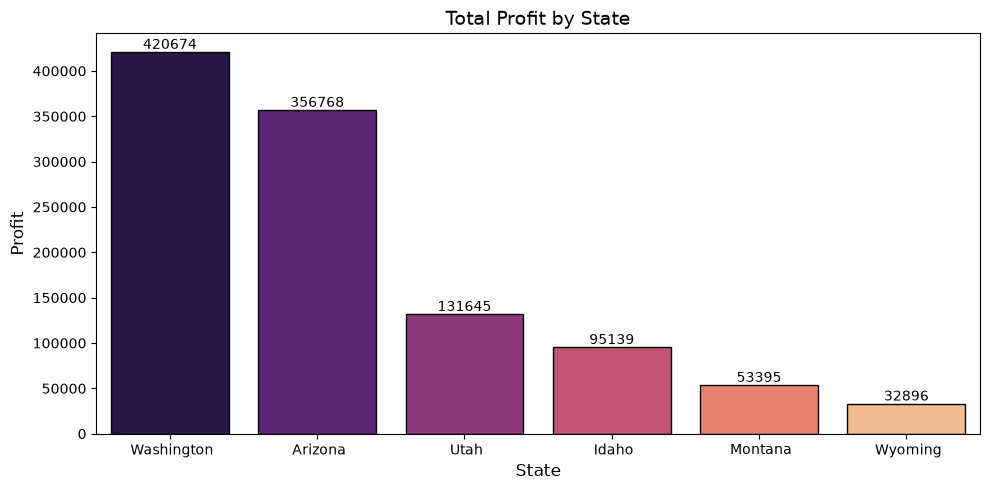

In [59]:
profit_state = (
    df_clean.groupby('State')['Profit']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))  

ax1 = sns.barplot(
    data=profit_state,
    x='State',
    y='Profit',
    hue='State',             
    palette='magma',
    legend=False,
    edgecolor='black'
)

for container in ax1.containers:
    ax1.bar_label(container, fmt='%.0f')

plt.xlabel("State", fontsize=12)
plt.ylabel("Profit", fontsize=12)
plt.title("Total Profit by State", fontsize=14)
plt.tight_layout()
plt.show()  

### Interpretation

Washington generated the highest total profit, followed by Arizona.
States with lower total profits contributed significantly less to the company's overall profitability.
This indicates that Trina's strongest financial performance is concentrated in only a few states.

## Total Revenue by State

This visualization shows the total revenue generated in each state during the 2016–2017 period.

Revenue reflects the total sales volume before taxes and expenses. Comparing revenue across states helps identify the company's strongest markets and provides additional context for interpreting profitability.

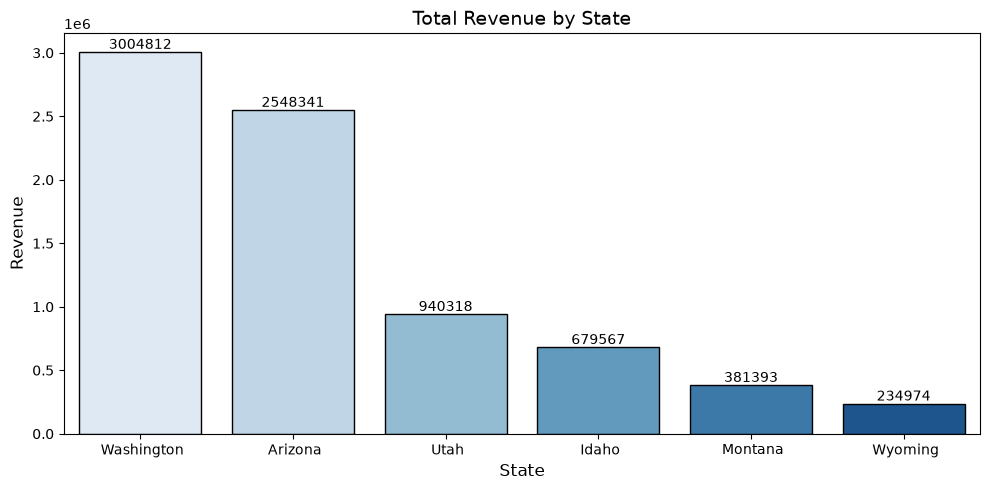

In [60]:
revenue_state = (
    df_clean.groupby("State")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))  # WICHTIG: Neues Fenster für Grafik 2

ax2 = sns.barplot(
    data=revenue_state,
    x="State",
    y="Revenue",
    hue="State",
    palette="Blues",
    legend=False,
    edgecolor="black"
)

for container in ax2.containers:
    ax2.bar_label(container, fmt="%.0f")

plt.title("Total Revenue by State", fontsize=14)
plt.xlabel("State", fontsize=12)
plt.ylabel("Revenue", fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation

The chart shows that Washington generated the highest total revenue, followed by Arizona. These two states clearly outperform the remaining states in terms of sales volume.

Although high revenue does not automatically guarantee high profitability, it provides an important explanation for why Washington and Arizona also rank among the strongest states in terms of overall profit. States with lower revenue contribute less to the company's total financial performance.

## Average Post-Tax Profit Margin by State

This visualization compares the average post-tax profit margin across all states.

The post-tax profit margin measures how much profit remains after taxes relative to revenue. It provides insight into how efficiently each state converts revenue into profit after accounting for tax obligations.

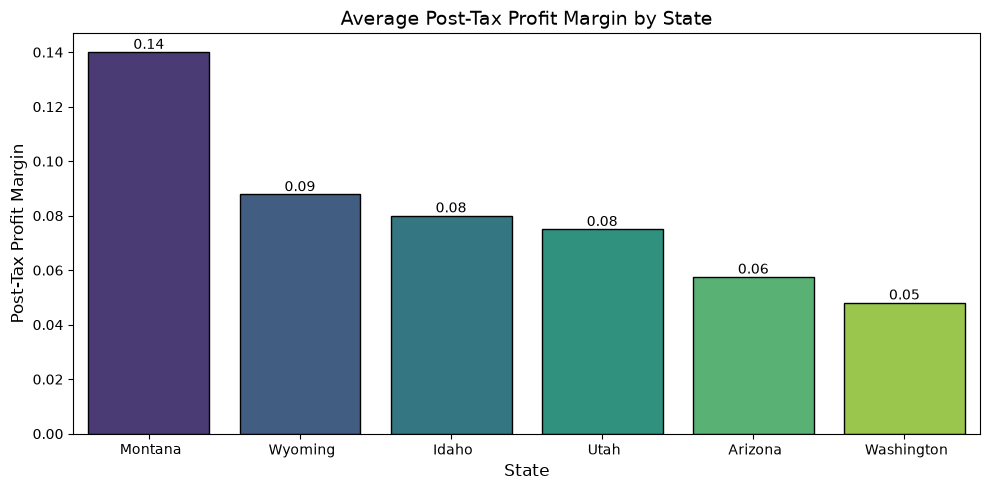

In [61]:
margin_state = (
    df_clean.groupby('State')['PostTaxProfitMargin']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))

ax3 = sns.barplot(
    data=margin_state,
    x='State',
    y='PostTaxProfitMargin',
    hue='State',
    palette='viridis',
    legend=False,
    edgecolor='black'
)

for container in ax3.containers:
    ax3.bar_label(container, fmt='%.2f')

plt.title("Average Post-Tax Profit Margin by State", fontsize=14)
plt.xlabel("State", fontsize=12)
plt.ylabel("Post-Tax Profit Margin", fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation

The results show noticeable differences in the average post-tax profit margin between states. States with a higher margin retain a larger share of their revenue as profit after taxes, indicating more efficient operations.

Comparing this chart with the revenue and profit visualizations reveals that high revenue alone does not guarantee a high post-tax profit margin. Instead, operational efficiency and the overall tax burden also influence how much profit is ultimately retained.

## Average Total Tax Rate by State

This visualization compares the average total tax rate across all states.

The total tax rate is calculated by combining the state tax rate, county tax rate, and city tax rate. Analyzing the average tax burden helps evaluate whether higher taxes are associated with lower post-tax profitability.

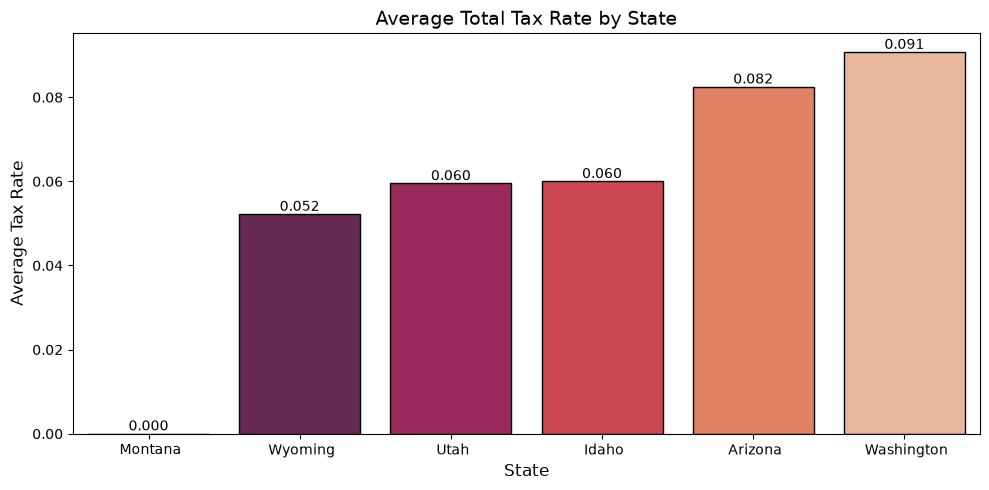

In [62]:
df_clean["TotalTaxRate"] = (
    df_clean["StateRate"]
    + df_clean["EstimatedCountyRate"]
    + df_clean["EstimatedCityRate"]
)

tax_state = (
    df_clean.groupby("State")["TotalTaxRate"]
    .mean()
    .sort_values()
    .reset_index()
)

plt.figure(figsize=(10, 5))

ax4 = sns.barplot(
    data=tax_state,
    x="State",
    y="TotalTaxRate",
    hue="State",
    palette="rocket",
    legend=False,
    edgecolor="black"
)

for container in ax4.containers:
    ax4.bar_label(container, fmt="%.3f")

plt.title("Average Total Tax Rate by State", fontsize=14)
plt.xlabel("State", fontsize=12)
plt.ylabel("Average Tax Rate", fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation

The chart shows that the average total tax rate differs across states due to variations in state, county, and city taxes.

Although some states have a higher overall tax burden, the previous visualizations indicate that higher taxes do not necessarily result in lower profitability. States with strong revenue and efficient operations can still achieve high post-tax profits despite relatively higher tax rates.

This suggests that tax burden is an important factor, but it is not the only determinant of overall business performance.

Data Classification

In [63]:
import pandas as pd
import DataCleaning as df
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Verknüpft mit df_clean
df_classification = df.df_clean

In [64]:
margin_median = df_classification["PostTaxProfitMargin"].median()
print(margin_median)
df.df_clean["HighProfitability"] = (
    df_classification["PostTaxProfitMargin"]
    > margin_median
).astype(int)


print(df_classification["HighProfitability"].value_counts())
# Die zeilen mit Profitabilität werden aufgedeckt 
# 1 = 188692 Zeilen; 0 = 197245

0.05800000000000001
HighProfitability
0    197245
1    188692
Name: count, dtype: int64


In [65]:
feature_columns = [
    "ETR",
    "Revenue"] 
# -> Einzeln abchecken also in 2 aufteieln! weil ETR alle zusammen ist das hier ist jetzt verdoppelt  

feature_columns_tax = [
    "StateRate",
    "EstimatedCountyRate",
    "EstimatedCityRate",
    "EstimatedSpecialRate",
    "Revenue"]    

In [66]:
X = df_classification[feature_columns]
y = df_classification["HighProfitability"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=12,
    stratify=y
)

In [67]:
fit1 = LogisticRegression(
    random_state=0,
    max_iter=1000
)

fit1.fit(X_train, y_train)

y_pred = fit1.predict(X_test)

In [68]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy: ", accuracy)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report( y_test, y_pred))

Accuracy:  0.5565243302067678
Confusion Matrix:
[[22612 16837]
 [17394 20345]]
Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.57      0.57     39449
           1       0.55      0.54      0.54     37739

    accuracy                           0.56     77188
   macro avg       0.56      0.56      0.56     77188
weighted avg       0.56      0.56      0.56     77188



In [69]:
print("Intercept: ")
print(fit1.intercept_)

print("Coefficients: ")
print(fit1.coef_)

Intercept: 
[0.51750924]
Coefficients: 
[[-1.24202103e+01 -1.44803449e-03]]


In [70]:
# Wahrscheinlichkeit für das gesamte Dataset
df_classification["HighProfitabilityProbability"] = (
    fit1.predict_proba(X)[:, 1]
)

# Ergebnisse pro State zusammenfassen
state_results = (
    df_classification.groupby("State")
    .agg(
        AverageProbability=(
            "HighProfitabilityProbability",
            "mean"),

        AveragePostTaxMargin=(
            "PostTaxProfitMargin",
            "mean"),

        TotalProfit=(
            "Profit",
            "sum"),

        TotalRevenue=(
            "Revenue",
            "sum"),

        AverageETR=(
            "ETR",
            "mean"),

        Transactions=(
            "State",
            "size")).reset_index()
)

# Nach Wahrscheinlichkeit für hohe Profitabilität sortieren
state_results = state_results.sort_values(
    by="AverageProbability",
    ascending=False
)

print(state_results)

         State  AverageProbability  AveragePostTaxMargin  TotalProfit  \
0      Arizona            0.619966              0.057523  356767.6910   
1        Idaho            0.619780              0.080000   95139.4304   
2      Montana            0.619730              0.140000   53394.9948   
5      Wyoming            0.459971              0.087796   32896.4258   
3         Utah            0.412226              0.075000  131644.5410   
4   Washington            0.342140              0.048046  420673.6282   

   TotalRevenue  AverageETR  Transactions  
0    2548340.65    0.000000        132421  
1     679567.36    0.000000         34357  
2     381392.82    0.000000         19149  
5     234974.47    0.052204         11419  
3     940318.15    0.068180         52666  
4    3004811.63    0.091954        135925  


In [71]:
state_results["AverageProbability"] = (
    state_results["AverageProbability"] * 100
)

state_results["AveragePostTaxMargin"] = (
    state_results["AveragePostTaxMargin"] * 100
)

state_results["AverageETR"] = (
    state_results["AverageETR"] * 100
)

print(
    state_results.round({
        "AverageProbability": 2,
        "AveragePostTaxMargin": 2,
        "TotalProfit": 2,
        "TotalRevenue": 2,
        "AverageETR": 2
    })
)

print(
    state_results[
        [
            "State",
            "AverageProbability",
            "AveragePostTaxMargin",
            "TotalProfit",
            "TotalRevenue",
            "AverageETR",
            "Transactions"
        ]
    ].to_string(index=False)
)

         State  AverageProbability  AveragePostTaxMargin  TotalProfit  \
0      Arizona               62.00                  5.75    356767.69   
1        Idaho               61.98                  8.00     95139.43   
2      Montana               61.97                 14.00     53394.99   
5      Wyoming               46.00                  8.78     32896.43   
3         Utah               41.22                  7.50    131644.54   
4   Washington               34.21                  4.80    420673.63   

   TotalRevenue  AverageETR  Transactions  
0    2548340.65        0.00        132421  
1     679567.36        0.00         34357  
2     381392.82        0.00         19149  
5     234974.47        5.22         11419  
3     940318.15        6.82         52666  
4    3004811.63        9.20        135925  
      State  AverageProbability  AveragePostTaxMargin  TotalProfit  TotalRevenue  AverageETR  Transactions
    Arizona           61.996570              5.752294  356767.6910    254

## Clustering: Tax Profile and Profitability Across States

In this section we group Trina's transactions using K-Means based on their tax profile
(state, county, city and special tax rates). The goal is to understand whether the
states can be separated into clearly distinct groups by their tax burden, and how these
groups differ in their post-tax profit margin. This addresses Trina's core question of
where she operates most profitably.

In [72]:
# Safety step: remove whitespace in 'State' (in case it wasn't done during cleaning)
df_clean["State"] = df_clean["State"].str.strip()

# Features: state (categorical) + the four tax rates
short = df_clean[["State",
                  "StateRate",
                  "EstimatedCountyRate",
                  "EstimatedCityRate",
                  "EstimatedSpecialRate"]]

# K-Means needs numbers -> convert the categorical column 'State' into dummy variables
short_dummys = pd.get_dummies(short)
short_dummys.columns.tolist()

['StateRate',
 'EstimatedCountyRate',
 'EstimatedCityRate',
 'EstimatedSpecialRate',
 'State_Arizona',
 'State_Idaho',
 'State_Montana',
 'State_Utah',
 'State_Washington',
 'State_Wyoming']

K-Means can only work with numerical values. We therefore convert the text column
`State` into six 0/1 columns using `pd.get_dummies()` (e.g. `State_Montana`). The four
tax rates all lie in a range of roughly 0 to 0.065 and are therefore naturally
comparable, so no additional scaling is required.

In [73]:
# K-Means clustering (parameters as used in the lecture)
kmeans = KMeans(n_clusters=4, max_iter=1000, random_state=12)
kmeans.fit(short_dummys)
df_clean["Cluster"] = kmeans.labels_

# Centroids = average profile of each cluster
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=short_dummys.columns)
print(centroids.round(3))
print(df_clean["Cluster"].value_counts())

   StateRate  EstimatedCountyRate  EstimatedCityRate  EstimatedSpecialRate  \
0      0.065                0.003              0.023                 0.001   
1      0.057                0.006              0.015                -0.000   
2      0.046                0.004              0.008                 0.005   
3     -0.000               -0.000              0.000                 0.000   

   State_Arizona  State_Idaho  State_Montana  State_Utah  State_Washington  \
0         -0.000       -0.000           -0.0       0.000               1.0   
1          0.794        0.206           -0.0       0.000               0.0   
2         -0.000       -0.000            0.0       0.822              -0.0   
3         -0.000        0.000            1.0      -0.000               0.0   

   State_Wyoming  
0         -0.000  
1         -0.000  
2          0.178  
3          0.000  
Cluster
1    166778
0    135925
2     64085
3     19149
Name: count, dtype: int64


We form four clusters. Each transaction is assigned a cluster number, and the centroids
show the average tax and state profile of each group. The four clusters are reasonably
balanced in size, which indicates a meaningful grouping.

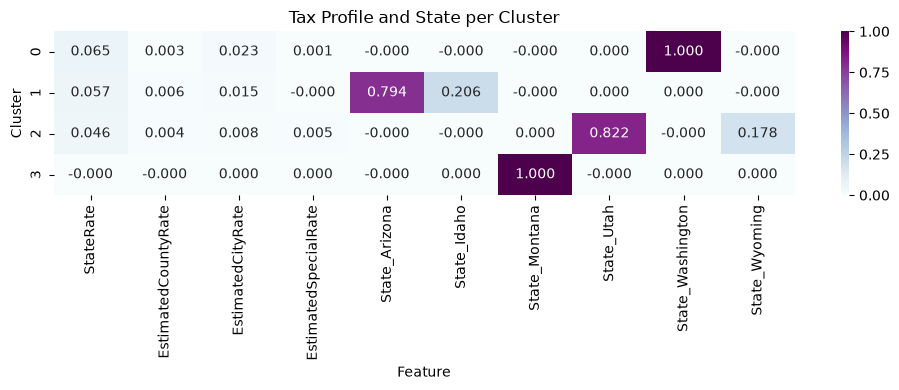

In [74]:
# Heatmap of the cluster profiles (as in the lecture)
plt.rcParams["figure.figsize"] = (10, 4)
sns.heatmap(centroids, annot=True, cmap="BuPu", fmt=".3f")
plt.title("Tax Profile and State per Cluster")
plt.xlabel("Feature")
plt.ylabel("Cluster")
plt.tight_layout()

**Interpretation of the heatmap:** Each cluster row is dominated by exactly one state
(dark cell in the state columns). The cluster containing Montana shows a value of zero
for all tax rates and therefore represents the tax-free zone. The cluster containing
Washington has the highest city tax. The clustering thus clearly separates the states
by their tax burden.

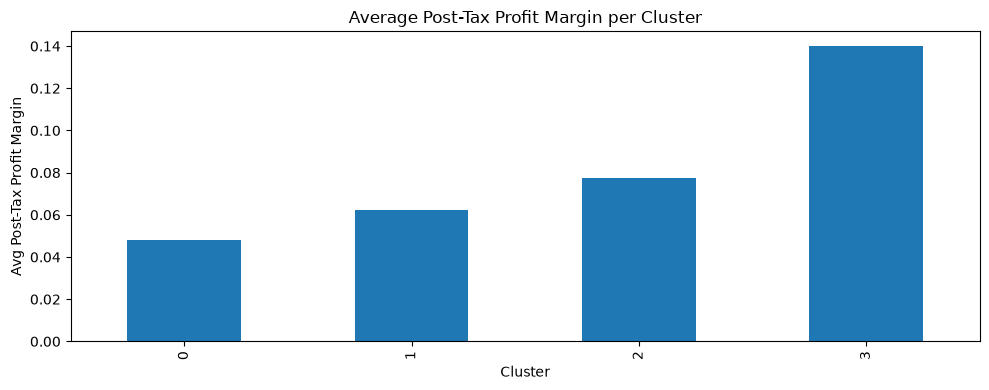

In [75]:
# Average post-tax profit margin per cluster (as in the lecture)
df_clean.groupby("Cluster")["PostTaxProfitMargin"].mean().plot(kind="bar")
plt.title("Average Post-Tax Profit Margin per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Avg Post-Tax Profit Margin")
plt.tight_layout()

**Interpretation of the bar chart:** There is a clear relationship between tax burden
and profitability. The cluster containing Montana (tax-free) reaches the highest
post-tax margin at around 14%, while the cluster containing Washington (highest tax
burden) reaches the lowest at around 4.8%. For Trina this means that states with a lower
tax burden are considerably more profitable and should be prioritized when expanding.
The location is therefore the decisive lever for Trina's profitability.

# The Forecast

In [76]:
df_clean["InvoiceMonth"] = pd.to_datetime(df_clean["InvoiceDate"]).dt.month #create a month variable for the linear Regression
# variables for the posttaxprofit
df_clean["PostTaxProfitIfNexus"] = df_clean["Profit"]-df_clean["SalesTaxNoNexus"] 
df_clean["ActualPostTaxProfit"] = df_clean["Profit"] - df_clean["SalesTaxOwed"]
# group dataframe for linear regression
df_grouped = df_clean.groupby(by=["State", "InvoiceYear", "InvoiceMonth"])[["ActualPostTaxProfit", "PostTaxProfitIfNexus"]].sum().reset_index()
df_grouped
growth_trends = []

# loop to predict the profit for all states
for state in df_grouped["State"].unique():
    df_state = df_grouped[df_grouped["State"] == state].copy()
    # add the time index
    df_state["time"] = range(len(df_state))

    if len(df_state) > 1:
        #predict profit for the actual profit
        model_actual = linear_model.LinearRegression()
        model_actual.fit(df_state[["time"]], df_state[["ActualPostTaxProfit"]])
        actual_post_tax_profit_growth = model_actual.coef_[0][0]
        
        #predict profit for the profitif there was a nexus
        model_ifnexus = linear_model.LinearRegression()
        model_ifnexus.fit(df_state[["time"]], df_state[["PostTaxProfitIfNexus"]])
        post_tax_profit_ifnexus_growth = model_ifnexus.coef_[0][0]


        # prediction for next month
        next_month_index = len(df_state)
        # save and append the predictions and the growth in the list
        growth_trends.append({
            "State": state,
            "ActualPostTaxProfit": model_actual.predict([[next_month_index]])[0][0],
            "ActualPostTaxProfitGrowth": actual_post_tax_profit_growth,
            "PostTaxProfitIfNexus": model_ifnexus.predict([[next_month_index]])[0][0],
            "PostTaxProfitIfNexusGrowth": post_tax_profit_ifnexus_growth
        })
# put list into dataframe
df_trends = pd.DataFrame(growth_trends)
df_trends

#create a multiple bar diagram to compare the profits 
df_trends.plot(kind="bar",x="State", y=["ActualPostTaxProfit", "PostTaxProfitIfNexus"])

plt.xlabel("State", fontsize =12)
plt.ylabel("Profit after Tax", fontsize = 12)
plt.title("Comparison between the prognosted actual profit and the profit if there was a nexus", fontsize =15)



                                             




NameError: name 'linear_model' is not defined